# 🔍 DIAGNOSTIC_train_test_shift — Cek Pergeseran Rezim Volatilitas (Train vs Test)
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Ilda Nurida — 6032251068 | Pembimbing: Dr. Ir. Ahmad Saikhu, S.Si, MT.**

### 🎯 Tujuan
Learning curve LSTM (`MODEL_lstm_v3.ipynb`, CELL 7) menunjukkan training **sehat** (train loss & val loss konvergen berdekatan) untuk 6 dari 7 emiten, TAPI beberapa di antaranya (mis. ADRO, PGAS) tetap punya R² buruk di **test set** (`tabel_evaluasi_lstm.csv`). Learning curve dihitung dari split *train vs validation* (bagian dari data train), sedangkan R² dihitung di *test set* yang sepenuhnya terpisah secara kronologis (20% terakhir).

Kalau training sehat tapi test tetap buruk, dugaan paling masuk akal adalah **distribution shift**: periode test (kronologis paling akhir) punya karakteristik volatilitas yang secara struktural berbeda dari periode train — bukan overfitting biasa, tapi pola yang dipelajari model dari masa lalu tidak lagi berlaku di rezim pasar terbaru.

Notebook ini mengecek dugaan itu secara langsung: membandingkan distribusi `Volatilitas_Target` di **train** vs **test** per emiten, baik secara statistik (uji Kolmogorov–Smirnov) maupun visual (plot deret waktu dengan garis pemisah).

### ⚠️ Catatan Metodologis
Ini murni **diagnostik eksploratif** untuk membantu interpretasi Bab 4/5 — bukan bagian dari pipeline model/evaluasi utama, dan tidak menulis ulang file model manapun.

---
## ⚙️ CELL 1 — Import, Konfigurasi Path (identik notebook lain)

In [2]:

import os, warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

SEED = 42
np.random.seed(SEED)

plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 11,
    'figure.dpi': 150
})

# ── ROOT auto-detect (identik notebook lain) ──
ROOT = Path(os.getcwd())
for _ in range(6):
    if (ROOT / '03_dataset').exists(): break
    ROOT = ROOT.parent
if not (ROOT / '03_dataset').exists():
    ROOT = Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')

DIR_FINAL  = ROOT / '03_dataset' / 'final'
DIR_TABEL  = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'
for d in (DIR_TABEL, DIR_GAMBAR):
    d.mkdir(parents=True, exist_ok=True)

URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']
KOLOM_Y = 'Volatilitas_Target'   # identik seluruh pipeline

def muat_csv(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'File TIDAK ADA: {path.resolve()}')
    try:
        return pd.read_csv(path, encoding='utf-8-sig')
    except UnicodeDecodeError:
        return pd.read_csv(path)

print('=' * 70)
print('  🔍 DIAGNOSTIC TRAIN vs TEST SHIFT — KONFIGURASI SIAP')
print('=' * 70)
print(f'ROOT     : {ROOT}')
print(f'Emiten   : {URUTAN_EMITEN}')
print(f'KOLOM_Y  : {KOLOM_Y}')
print('=' * 70)


  🔍 DIAGNOSTIC TRAIN vs TEST SHIFT — KONFIGURASI SIAP
ROOT     : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
Emiten   : ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']
KOLOM_Y  : Volatilitas_Target


---
## 📂 CELL 2 — Muat `dataset_train_{emiten}.csv` & `dataset_test_{emiten}.csv`

Memakai file split kronologis yang SAMA persis dengan yang dipakai `MODEL_lstm_v3.ipynb` (bukan re-split baru) — supaya diagnostik ini benar-benar mencerminkan train/test yang dipakai model.

In [3]:

print('=' * 70)
print('  📂 CELL 2 — MUAT DATASET TRAIN & TEST PER EMITEN')
print('=' * 70)

dict_tr, dict_te = {}, {}

for emiten in URUTAN_EMITEN:
    p_tr = DIR_FINAL / f'dataset_train_{emiten}.csv'
    p_te = DIR_FINAL / f'dataset_test_{emiten}.csv'

    if not p_tr.exists() or not p_te.exists():
        print(f'  ⚠️  {emiten}: dataset_train/test tidak ditemukan, skip')
        continue

    df_tr = muat_csv(p_tr)
    df_te = muat_csv(p_te)

    for df in (df_tr, df_te):
        if 'Date' in df.columns:
            df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

    if KOLOM_Y not in df_tr.columns or KOLOM_Y not in df_te.columns:
        print(f'  ⚠️  {emiten}: kolom {KOLOM_Y} tidak ditemukan, skip')
        continue

    df_tr = df_tr.dropna(subset=[KOLOM_Y]).reset_index(drop=True)
    df_te = df_te.dropna(subset=[KOLOM_Y]).reset_index(drop=True)

    dict_tr[emiten] = df_tr
    dict_te[emiten] = df_te

    tgl_tr = (str(df_tr['Date'].min().date()) + ' s/d ' + str(df_tr['Date'].max().date())) if 'Date' in df_tr.columns else 'n/a'
    tgl_te = (str(df_te['Date'].min().date()) + ' s/d ' + str(df_te['Date'].max().date())) if 'Date' in df_te.columns else 'n/a'
    print(f'  ✅ {emiten:<5}: train={len(df_tr):4d} baris ({tgl_tr}) | test={len(df_te):4d} baris ({tgl_te})')

print(f'\nTotal emiten siap: {len(dict_tr)}/{len(URUTAN_EMITEN)}')


  📂 CELL 2 — MUAT DATASET TRAIN & TEST PER EMITEN
  ✅ ADRO : train= 836 baris (2022-01-28 s/d 2025-08-01) | test= 209 baris (2025-08-04 s/d 2026-06-15)
  ✅ ADMR : train= 836 baris (2022-01-28 s/d 2025-08-01) | test= 209 baris (2025-08-04 s/d 2026-06-15)
  ✅ ITMG : train= 836 baris (2022-01-28 s/d 2025-08-01) | test= 209 baris (2025-08-04 s/d 2026-06-15)
  ✅ PTBA : train= 836 baris (2022-01-28 s/d 2025-08-01) | test= 209 baris (2025-08-04 s/d 2026-06-15)
  ✅ MEDC : train= 836 baris (2022-01-28 s/d 2025-08-01) | test= 209 baris (2025-08-04 s/d 2026-06-15)
  ✅ AKRA : train= 836 baris (2022-01-28 s/d 2025-08-01) | test= 209 baris (2025-08-04 s/d 2026-06-15)
  ✅ PGAS : train= 836 baris (2022-01-28 s/d 2025-08-01) | test= 209 baris (2025-08-04 s/d 2026-06-15)

Total emiten siap: 7/7


---
## 📊 CELL 3 — Statistik Deskriptif: Train vs Test per Emiten

In [4]:

print('=' * 70)
print('  📊 CELL 3 — STATISTIK DESKRIPTIF VOLATILITAS_TARGET: TRAIN vs TEST')
print('=' * 70)

baris_stat = []
for emiten in URUTAN_EMITEN:
    if emiten not in dict_tr:
        continue
    y_tr = dict_tr[emiten][KOLOM_Y]
    y_te = dict_te[emiten][KOLOM_Y]

    baris_stat.append({
        'Emiten': emiten,
        'Mean_Train': round(y_tr.mean(), 5), 'Mean_Test': round(y_te.mean(), 5),
        'Std_Train': round(y_tr.std(), 5), 'Std_Test': round(y_te.std(), 5),
        'Min_Train': round(y_tr.min(), 5), 'Min_Test': round(y_te.min(), 5),
        'Max_Train': round(y_tr.max(), 5), 'Max_Test': round(y_te.max(), 5),
        'Rasio_Mean_Test/Train': round(y_te.mean() / y_tr.mean(), 3) if y_tr.mean() != 0 else np.nan,
    })

df_stat = pd.DataFrame(baris_stat)
pd.set_option('display.width', 200, 'display.max_columns', None)
print(df_stat.to_string(index=False))

print()
print('ℹ️  Interpretasi cepat: Rasio_Mean_Test/Train jauh dari 1.0 (mis. >1.3 atau <0.7)')
print('   mengindikasikan level volatilitas rata-rata di periode test jauh berbeda dari train --')
print('   sinyal awal distribution shift.')


  📊 CELL 3 — STATISTIK DESKRIPTIF VOLATILITAS_TARGET: TRAIN vs TEST
Emiten  Mean_Train  Mean_Test  Std_Train  Std_Test  Min_Train  Min_Test  Max_Train  Max_Test  Rasio_Mean_Test/Train
  ADRO     0.19947    0.18336    0.15188   0.07883        0.0   0.04370        1.0   0.40446                  0.919
  ADMR     0.23893    0.27683    0.12515   0.14064        0.0   0.06159        1.0   0.59410                  1.159
  ITMG     0.40998    0.29582    0.22860   0.28638        0.0  -0.01971        1.0   1.01979                  0.722
  PTBA     0.22806    0.15371    0.16062   0.15105        0.0  -0.03394        1.0   0.50076                  0.674
  MEDC     0.36305    0.38460    0.19337   0.19068        0.0   0.04156        1.0   0.80286                  1.059
  AKRA     0.26668    0.25829    0.16257   0.10134        0.0   0.00412        1.0   0.47834                  0.969
  PGAS     0.43601    0.49342    0.21496   0.30525        0.0   0.16738        1.0   1.34255                  1.132

ℹ️ 

---
## 🧪 CELL 4 — Uji Statistik: Kolmogorov–Smirnov (Distribusi Train vs Test)

Uji KS dua-sampel menguji apakah `Volatilitas_Target` di train dan test berasal dari distribusi yang sama. **p-value < 0.05** → cukup bukti bahwa distribusinya berbeda signifikan (indikasi distribution shift), bukan sekadar variasi acak.

In [5]:

print('=' * 70)
print('  🧪 CELL 4 — UJI KOLMOGOROV-SMIRNOV: TRAIN vs TEST')
print('=' * 70)

baris_ks = []
for emiten in URUTAN_EMITEN:
    if emiten not in dict_tr:
        continue
    y_tr = dict_tr[emiten][KOLOM_Y].values
    y_te = dict_te[emiten][KOLOM_Y].values

    ks_stat, p_value = stats.ks_2samp(y_tr, y_te)
    signifikan = 'YA -- ada shift' if p_value < 0.05 else 'Tidak'

    baris_ks.append({
        'Emiten': emiten, 'KS_Statistic': round(ks_stat, 4),
        'p_value': round(p_value, 5), 'Shift_Signifikan (p<0.05)': signifikan,
    })
    tanda = '⚠️ ' if p_value < 0.05 else '✅ '
    print('  ' + tanda + f'{emiten:<5}: KS={ks_stat:.4f}, p-value={p_value:.5f} -> {signifikan}')

df_ks = pd.DataFrame(baris_ks)
path_ks = DIR_TABEL / 'tabel_diagnostic_ks_train_test.csv'
df_ks.to_csv(path_ks, index=False, encoding='utf-8-sig')
print(f'\n💾 Tabel disimpan: {path_ks}')


  🧪 CELL 4 — UJI KOLMOGOROV-SMIRNOV: TRAIN vs TEST
  ✅ ADRO : KS=0.0813, p-value=0.21170 -> Tidak
  ⚠️ ADMR : KS=0.1890, p-value=0.00001 -> YA -- ada shift
  ⚠️ ITMG : KS=0.4043, p-value=0.00000 -> YA -- ada shift
  ⚠️ PTBA : KS=0.3553, p-value=0.00000 -> YA -- ada shift
  ⚠️ MEDC : KS=0.1136, p-value=0.02535 -> YA -- ada shift
  ⚠️ AKRA : KS=0.1196, p-value=0.01584 -> YA -- ada shift
  ⚠️ PGAS : KS=0.1112, p-value=0.03040 -> YA -- ada shift

💾 Tabel disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\tabel\tabel_diagnostic_ks_train_test.csv


---
## 📈 CELL 5 — Visualisasi: Deret Waktu Volatilitas dengan Garis Pemisah Train/Test

Biru = periode train, oranye = periode test. Garis putus-putus vertikal menandai batas split kronologis. Perhatikan apakah level/pola volatilitas di area oranye terlihat jelas berbeda (lebih tinggi/rendah/lebih fluktuatif) dibanding area biru.

  📈 CELL 5 — VISUALISASI TRAIN vs TEST PER EMITEN


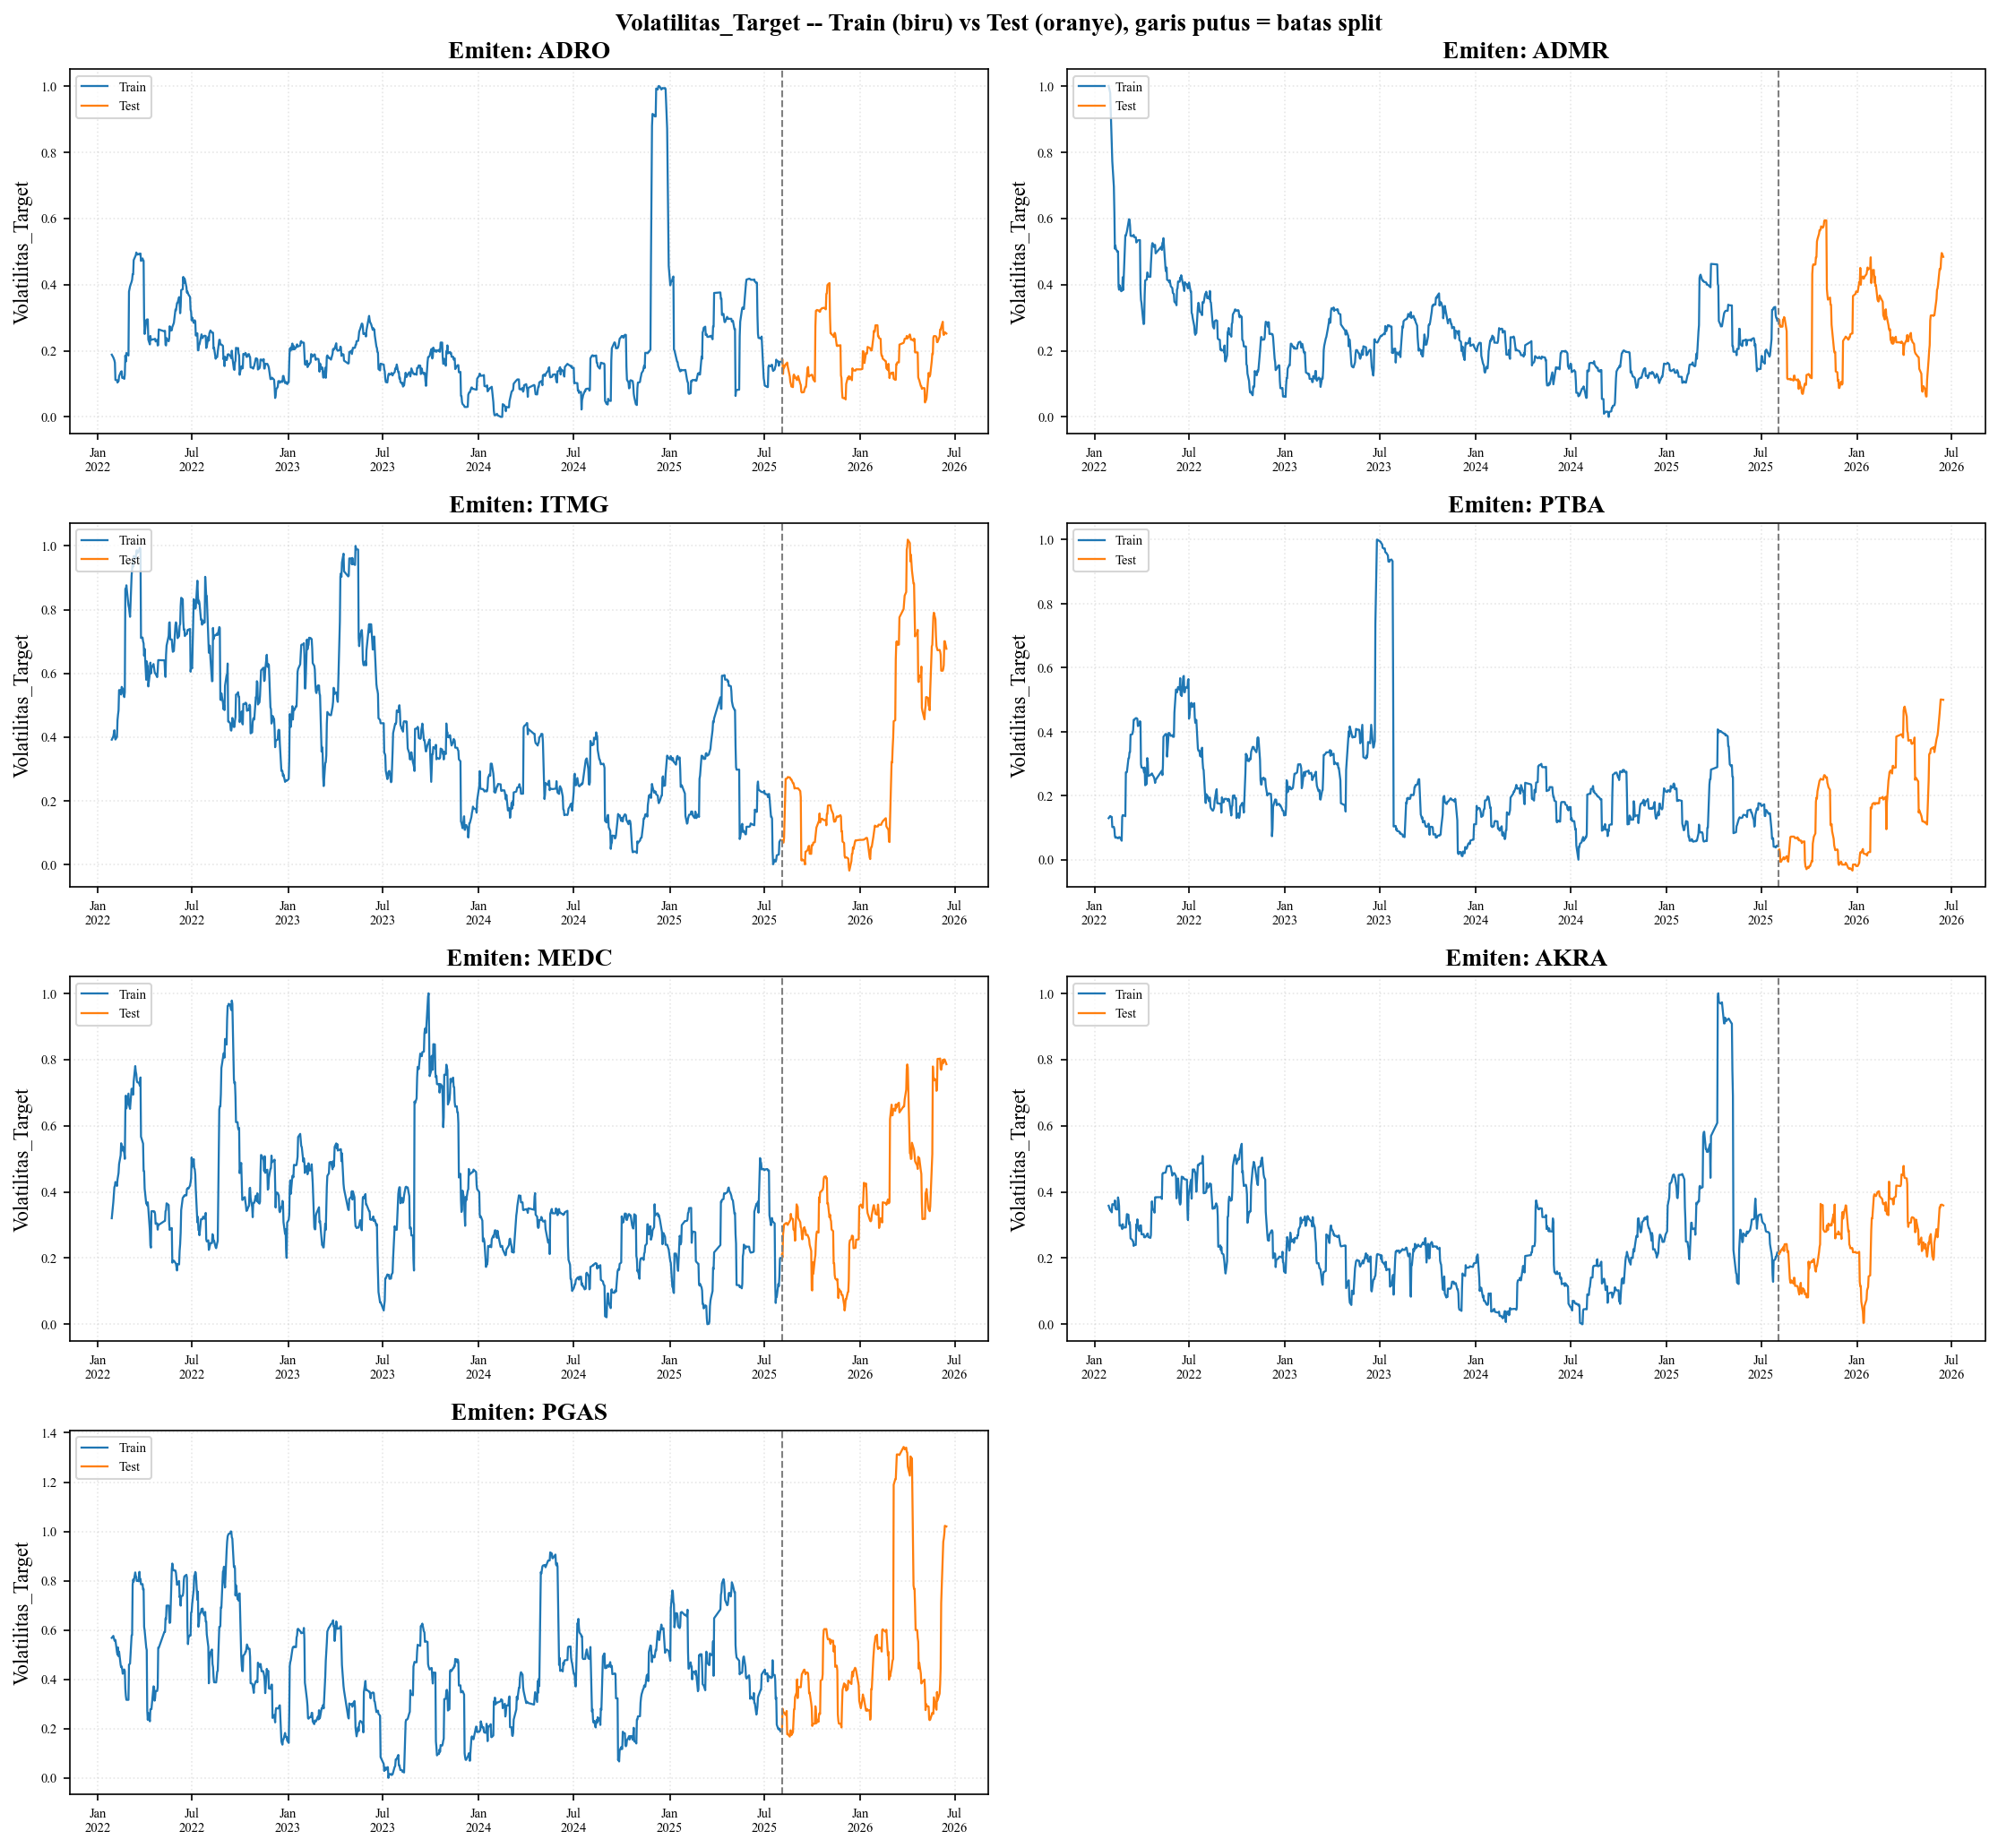

💾 Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model\gambar_diagnostic_train_test_shift.png


In [6]:

print('=' * 70)
print('  📈 CELL 5 — VISUALISASI TRAIN vs TEST PER EMITEN')
print('=' * 70)

emiten_ok = [e for e in URUTAN_EMITEN if e in dict_tr]
ncol = 2
nrow = int(np.ceil(len(emiten_ok) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.5 * nrow))
axes = np.array(axes).ravel()

for ax, emiten in zip(axes, emiten_ok):
    d_tr = dict_tr[emiten]
    d_te = dict_te[emiten]

    ax.plot(d_tr['Date'], d_tr[KOLOM_Y], color='#1f77b4', lw=1.1, label='Train')
    ax.plot(d_te['Date'], d_te[KOLOM_Y], color='#ff7f0e', lw=1.1, label='Test')

    batas = d_te['Date'].min()
    ax.axvline(batas, color='gray', linestyle='--', lw=1)

    ax.set_title(f'Emiten: {emiten}', fontweight='bold')
    ax.set_ylabel('Volatilitas_Target')
    ax.legend(fontsize=7, loc='upper left')
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.3, linestyle=':')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))

for ax in axes[len(emiten_ok):]:
    ax.axis('off')

plt.suptitle('Volatilitas_Target -- Train (biru) vs Test (oranye), garis putus = batas split',
             fontweight='bold', fontsize=13)
plt.tight_layout()
path_fig = DIR_GAMBAR / 'gambar_diagnostic_train_test_shift.png'
plt.savefig(path_fig, dpi=150, bbox_inches='tight')
plt.show()
print(f'💾 Gambar disimpan: {path_fig}')


---
## 🧾 CELL 6 — Ringkasan Otomatis: Silangkan dengan R² LSTM

Cocokkan emiten yang terindikasi shift (CELL 4) dengan performa test set LSTM (`tabel_evaluasi_lstm.csv`) — kalau ada file itu, akan digabung otomatis. Kalau belum ada / path beda, cell ini tetap jalan tapi cuma menampilkan hasil KS test.

In [7]:

print('=' * 70)
print('  🧾 CELL 6 — RINGKASAN: DISTRIBUTION SHIFT vs PERFORMA LSTM')
print('=' * 70)

path_eval_lstm = DIR_TABEL / 'tabel_evaluasi_lstm.csv'

if path_eval_lstm.exists():
    df_eval_lstm = muat_csv(path_eval_lstm)
    df_gab = df_ks.merge(
        df_eval_lstm[['Emiten', 'R2', 'RMSE', 'MAPE (%)']],
        on='Emiten', how='left'
    )
    pd.set_option('display.width', 220, 'display.max_columns', None)
    print(df_gab.to_string(index=False))

    print()
    shift_dan_buruk = df_gab[(df_gab['Shift_Signifikan (p<0.05)'] == 'YA -- ada shift') & (df_gab['R2'] < 0.5)]
    if len(shift_dan_buruk) > 0:
        print('⚠️  Emiten dengan shift signifikan DAN R2 LSTM rendah (<0.5) -- kandidat kuat')
        print('   "distribution shift" sebagai penyebab, bukan overfitting murni:')
        print('   ' + ', '.join(shift_dan_buruk['Emiten'].tolist()))
    else:
        print('ℹ️  Tidak ada emiten yang memenuhi kedua kriteria (shift signifikan + R2<0.5) sekaligus.')
else:
    print(f'⚠️  {path_eval_lstm} belum ditemukan -- jalankan MODEL_lstm_v3.ipynb dulu utk perbandingan otomatis.')
    print('   Hasil uji KS tetap tersedia di tabel_diagnostic_ks_train_test.csv.')

print()
print('=' * 70)
print('✅ DIAGNOSTIC SELESAI')
print(f'   Tabel statistik  : (lihat CELL 3, cetak langsung)')
print(f'   Tabel uji KS     : tabel_diagnostic_ks_train_test.csv')
print(f'   Gambar           : gambar_diagnostic_train_test_shift.png')
print('=' * 70)


  🧾 CELL 6 — RINGKASAN: DISTRIBUTION SHIFT vs PERFORMA LSTM
Emiten  KS_Statistic  p_value Shift_Signifikan (p<0.05)      R2     RMSE  MAPE (%)
  ADRO        0.0813  0.21170                     Tidak -0.1951 0.007138     29.29
  ADMR        0.1890  0.00001           YA -- ada shift  0.4357 0.010872     28.29
  ITMG        0.4043  0.00000           YA -- ada shift  0.8153 0.004200     22.62
  PTBA        0.3553  0.00000           YA -- ada shift  0.4463 0.006128     49.49
  MEDC        0.1136  0.02535           YA -- ada shift  0.6535 0.005823     14.81
  AKRA        0.1196  0.01584           YA -- ada shift -4.3665 0.013564     62.80
  PGAS        0.1112  0.03040           YA -- ada shift  0.2605 0.007014     20.42

⚠️  Emiten dengan shift signifikan DAN R2 LSTM rendah (<0.5) -- kandidat kuat
   "distribution shift" sebagai penyebab, bukan overfitting murni:
   ADMR, PTBA, AKRA, PGAS

✅ DIAGNOSTIC SELESAI
   Tabel statistik  : (lihat CELL 3, cetak langsung)
   Tabel uji KS     : tabel_d